# ParaDetox exploration for activation steering

This notebook audits `s-nlp/paradetox` before estimating a detoxification direction. The paired difference is defined as **neutral minus toxic**. The key leakage risk is that one toxic source can have multiple neutral paraphrases, so all splitting must happen by normalized toxic-source group rather than by row.

In [1]:
from collections import Counter
from difflib import SequenceMatcher
import re

from datasets import load_dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATASET_ID = "s-nlp/paradetox"
SOURCE_COLUMN = "en_toxic_comment"
TARGET_COLUMN = "en_neutral_comment"
SEED = 42

raw = load_dataset(DATASET_ID, split="train")
required = {SOURCE_COLUMN, TARGET_COLUMN}
assert required.issubset(raw.column_names), required - set(raw.column_names)
print(raw)
print("Columns:", raw.column_names)

/Users/nandanprince/Desktop/NLP_project/SecondThought/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Generating train split:   0%|          | 0/19744 [00:00<?, ? examples/s]

Generating train split: 100%|██████████| 19744/19744 [00:00<00:00, 540931.85 examples/s]

Dataset({
    features: ['en_toxic_comment', 'en_neutral_comment'],
    num_rows: 19744
})
Columns: ['en_toxic_comment', 'en_neutral_comment']


## 1. Validate the parallel corpus

Rows with empty text cannot produce meaningful directions. Exact copies are useful dataset diagnostics but contribute a zero vector, so the later direction experiment excludes them.

In [2]:
pairs = raw.select_columns([SOURCE_COLUMN, TARGET_COLUMN]).to_pandas().rename(
    columns={SOURCE_COLUMN: "toxic", TARGET_COLUMN: "neutral"}
)

def normalize_text(text):
    return " ".join(str(text).split()).casefold()

pairs["toxic"] = pairs["toxic"].fillna("").str.strip()
pairs["neutral"] = pairs["neutral"].fillna("").str.strip()
pairs["toxic_key"] = pairs["toxic"].map(normalize_text)
pairs["neutral_key"] = pairs["neutral"].map(normalize_text)
pairs["empty_pair"] = (pairs["toxic"] == "") | (pairs["neutral"] == "")
pairs["exact_copy"] = pairs["toxic_key"] == pairs["neutral_key"]
pairs["duplicate_pair"] = pairs.duplicated(["toxic_key", "neutral_key"], keep=False)

audit = pd.Series({
    "rows": len(pairs),
    "unique_toxic_sources": pairs["toxic_key"].nunique(),
    "unique_neutral_rewrites": pairs["neutral_key"].nunique(),
    "empty_pairs": int(pairs["empty_pair"].sum()),
    "exact_copies": int(pairs["exact_copy"].sum()),
    "rows_in_duplicate_pairs": int(pairs["duplicate_pair"].sum()),
    "mean_rewrites_per_toxic_source": len(pairs) / pairs["toxic_key"].nunique(),
})
display(audit.to_frame("value"))

,value
rows,19744.000000
unique_toxic_sources,11927.000000
unique_neutral_rewrites,18944.000000
empty_pairs,0.000000
exact_copies,132.000000
rows_in_duplicate_pairs,1430.000000
mean_rewrites_per_toxic_source,1.655404


## 2. Measure rewrite magnitude and surface changes

These diagnostics identify possible confounds. A detoxification direction may encode length, punctuation, capitalization, or lexical substitution in addition to toxicity removal.

In [3]:
WORD_PATTERN = re.compile(r"\b[\w']+\b", re.UNICODE)
TOXIC_MARKERS = {
    "ass", "asshole", "bastard", "bitch", "bullshit", "crap", "damn",
    "dick", "dumb", "fucking", "fuck", "hell", "idiot", "jerk",
    "moron", "shit", "stupid", "trash",
}

def words(text):
    return WORD_PATTERN.findall(text.casefold())

def marker_count(text):
    return sum(token in TOXIC_MARKERS for token in words(text))

pairs["toxic_words"] = pairs["toxic"].map(lambda text: len(words(text)))
pairs["neutral_words"] = pairs["neutral"].map(lambda text: len(words(text)))
pairs["word_count_ratio"] = pairs["neutral_words"] / pairs["toxic_words"].clip(lower=1)
pairs["character_similarity"] = [
    SequenceMatcher(None, left.casefold(), right.casefold()).ratio()
    for left, right in zip(pairs["toxic"], pairs["neutral"], strict=True)
]
pairs["toxic_marker_count"] = pairs["toxic"].map(marker_count)
pairs["neutral_marker_count"] = pairs["neutral"].map(marker_count)
pairs["marker_removed"] = pairs["neutral_marker_count"] < pairs["toxic_marker_count"]

display(pairs[[
    "toxic_words", "neutral_words", "word_count_ratio", "character_similarity",
    "toxic_marker_count", "neutral_marker_count",
]].describe(percentiles=[.05, .25, .5, .75, .95]).round(3))
print("Pairs where the small marker list detects removal:", f"{pairs['marker_removed'].mean():.1%}")

,toxic_words,neutral_words,word_count_ratio,character_similarity,toxic_marker_count,neutral_marker_count
count,19744.000,19744.000,19744.000,19744.000,19744.000,19744.000
mean,10.578,9.029,0.850,0.797,0.845,0.003
std,3.819,3.861,0.189,0.152,0.508,0.058
min,1.000,1.000,0.056,0.021,0.000,0.000
5%,5.000,4.000,0.538,0.473,0.000,0.000
25%,7.000,6.000,0.750,0.731,1.000,0.000
50%,10.000,8.000,0.867,0.844,1.000,0.000
75%,13.000,12.000,1.000,0.906,1.000,0.000
95%,17.000,16.000,1.100,0.954,2.000,0.000
max,20.000,26.000,10.000,1.000,5.000,1.000


Pairs where the small marker list detects removal: 78.5%


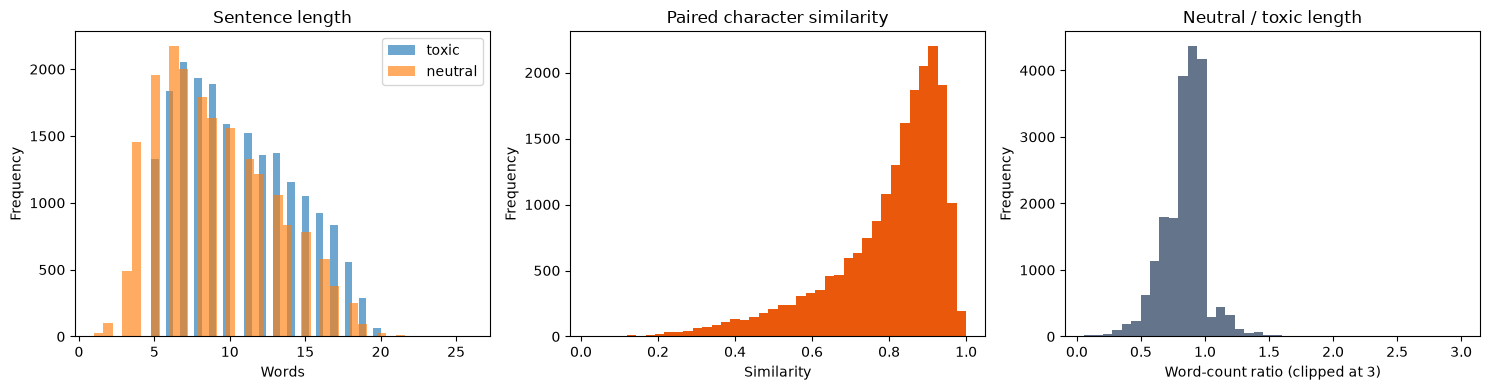

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pairs["toxic_words"].plot.hist(bins=40, alpha=.65, label="toxic", ax=axes[0])
pairs["neutral_words"].plot.hist(bins=40, alpha=.65, label="neutral", ax=axes[0])
axes[0].set(title="Sentence length", xlabel="Words")
axes[0].legend()
pairs["character_similarity"].plot.hist(bins=40, ax=axes[1], color="#ea580c")
axes[1].set(title="Paired character similarity", xlabel="Similarity")
pairs["word_count_ratio"].clip(upper=3).plot.hist(bins=40, ax=axes[2], color="#64748b")
axes[2].set(title="Neutral / toxic length", xlabel="Word-count ratio (clipped at 3)")
plt.tight_layout()

## 3. Inspect difficult pairs

Low-similarity and strongly length-altered pairs are the most likely to mix detoxification with paraphrasing or content deletion.

In [5]:
review_ids = pd.Index(np.concatenate([
    pairs.nsmallest(15, "character_similarity").index,
    pairs.nlargest(10, "word_count_ratio").index,
    pairs.nsmallest(10, "word_count_ratio").index,
])).unique()
display(pairs.loc[review_ids, [
    "character_similarity", "word_count_ratio", "toxic_marker_count",
    "neutral_marker_count", "toxic", "neutral",
]].sort_values("character_similarity").round(3))

,character_similarity,word_count_ratio,toxic_marker_count,neutral_marker_count,toxic,neutral
2740,0.021,0.071,0,0,true believers like you are nothing more than ...,Right
9993,0.028,0.083,1,0,"4 ! kindle & nook special , for her new releas...",4
13665,0.038,0.091,1,0,1 41 the price of starbucks for the same sugar...,1
2302,0.043,0.067,0,0,78 white men walk inarate christian churches a...,78
12668,0.047,0.067,1,0,40 billion and then send some fucking troops i...,40
13618,0.053,0.059,1,0,12 fucking years for actively collecting child...,twelve
14936,0.055,0.083,1,0,"23 % stock value losses overnight , even befor...",23
376,0.073,0.211,0,0,quit hiding behind your little computer screen...,Speak face to face.
310,0.073,0.056,1,0,true because the real criminal is the idiot le...,agree
513,0.074,0.056,1,0,true because the real criminal is the idiot le...,TRUE


## 4. Build a leakage-safe pool for direction extraction

We remove empty pairs, exact copies, and duplicate pairs. We then choose exactly one neutral rewrite for each normalized toxic source using a fixed seed. This prevents frequently paraphrased sources from dominating the mean direction and ensures that extraction and held-out splits cannot share a toxic source.

In [6]:
eligible = pairs.loc[~pairs["empty_pair"] & ~pairs["exact_copy"]].copy()
eligible = eligible.drop_duplicates(["toxic_key", "neutral_key"])
unique_source_pairs = (
    eligible.sample(frac=1, random_state=SEED)
    .drop_duplicates("toxic_key")
    .sort_values("toxic_key")
    .reset_index(drop=True)
)

print(f"Eligible parallel rows: {len(eligible):,}")
print(f"Unique toxic sources available for splitting: {len(unique_source_pairs):,}")
display(unique_source_pairs[["toxic", "neutral"]].head(10))

Eligible parallel rows: 18,872
Unique toxic sources available for splitting: 11,838


,toxic,neutral
0,! ! ! ! its overrer ! ! ! rt tru shit u right ...,It's true
1,! ! ! he gon beatcho ass as if you fucked up s...,He's going to punish you if you messed up some...
2,"! ! i hate makinn that movee , too damn longggg","I dont like makinn that movee, it takes too lo..."
3,"! a shark ate me , a fucking shark ate me !",a shark ate me.
4,! but it 's supposed to rain & shit .,! but it 's supposed to rain.
5,! get the fuck on the ground blam blam blam,Get on the ground blam blam blam
6,! how about you stop bombing shit and focus on...,! how about you stop bombing and focus on peac...
7,! the fuck kind of explanation is that for som...,The kind of explanation is that for something ...
8,! this station is the shit,This station is bad
9,! what the fuck do you think he was saying ? ? ?,What you think he was saying?


## Decision for the steering experiment

ParaDetox is appropriate for estimating a **neutral-minus-toxic direction**, but it is not a pure toxicity intervention dataset: neutral rewrites can also change grammar, length, politeness, specificity, and content. The hidden-state experiment must therefore use unseen toxic-source groups, shuffled-label controls, split-half stability, and independent output evaluation. A detected linear direction should initially be called a **ParaDetox detoxification direction**, not a universal toxicity axis.